# Taller final de minería de datos
## Segmentación de clientes con K-Means

En este trabajo se agrupan los clientes de un centro comercial según su ingreso y su puntuación de gasto. Se utiliza K-Means y se comparan distintos números de grupos con el método del codo y el coeficiente de silueta. Después se interpretan los resultados y se prepara una aplicación en Streamlit.

Para ejecutar el cuaderno en [Google Colab](https://colab.research.google.com/), se debe usar un entorno de Python 3 con CPU y seleccionar **Entorno de ejecución → Ejecutar todas**. El dataset ya está incluido y al final se descarga el paquete de la aplicación.

**Dataset:** [Mall Customer Segmentation Data, publicado por Vijay Choudhary en Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).

### Preparación del entorno

Primero se instalan las bibliotecas necesarias y se cargan las herramientas que se van a utilizar.

In [1]:
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

fixed_versions = {
    "scikit-learn": "1.7.2",
    "seaborn": "0.13.2",
    "streamlit": "1.50.0",
    "joblib": "1.5.2",
}
to_install = []
for package, expected in fixed_versions.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != expected:
        to_install.append(f"{package}=={expected}")
for package in ["numpy", "pandas", "scipy", "matplotlib"]:
    if importlib.util.find_spec(package) is None:
        to_install.append(package)
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *to_install])
print("Dependencias disponibles.")

Dependencias disponibles.


In [2]:
from pathlib import Path
import base64
import hashlib
import json
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, FileLink, display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
SEED = 42
N_INIT = 30
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]
NUMERIC = ["Age", *FEATURES]
SOURCE_URL = "https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python"
RESULTS = Path("resultados")
RESULTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)
versions = {name: metadata.version(name) for name in [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "streamlit", "joblib"
]}
display(pd.Series(versions, name="Versión").to_frame())

,Versión
numpy,2.0.2
pandas,2.2.2
scipy,1.15.3
scikit-learn,1.7.2
matplotlib,3.10.0
seaborn,0.13.2
streamlit,1.50.0
joblib,1.5.2


## Parte 1. Exploración de datos

Se revisan las columnas, los tipos de datos, los valores faltantes y las estadísticas principales. El ingreso anual está en miles de dólares y el Spending Score es una puntuación entre 1 y 100.

In [3]:
DATA_B64 = 'Q3VzdG9tZXJJRCxHZW5kZXIsQWdlLEFubnVhbCBJbmNvbWUgKGskKSxTcGVuZGluZyBTY29yZSAoMS0xMDApDQoxLE1hbGUsMTksMTUsMzkNCjIsTWFsZSwyMSwxNSw4MQ0KMyxGZW1hbGUsMjAsMTYsNg0KNCxGZW1hbGUsMjMsMTYsNzcNCjUsRmVtYWxlLDMxLDE3LDQwDQo2LEZlbWFsZSwyMiwxNyw3Ng0KNyxGZW1hbGUsMzUsMTgsNg0KOCxGZW1hbGUsMjMsMTgsOTQNCjksTWFsZSw2NCwxOSwzDQoxMCxGZW1hbGUsMzAsMTksNzINCjExLE1hbGUsNjcsMTksMTQNCjEyLEZlbWFsZSwzNSwxOSw5OQ0KMTMsRmVtYWxlLDU4LDIwLDE1DQoxNCxGZW1hbGUsMjQsMjAsNzcNCjE1LE1hbGUsMzcsMjAsMTMNCjE2LE1hbGUsMjIsMjAsNzkNCjE3LEZlbWFsZSwzNSwyMSwzNQ0KMTgsTWFsZSwyMCwyMSw2Ng0KMTksTWFsZSw1MiwyMywyOQ0KMjAsRmVtYWxlLDM1LDIzLDk4DQoyMSxNYWxlLDM1LDI0LDM1DQoyMixNYWxlLDI1LDI0LDczDQoyMyxGZW1hbGUsNDYsMjUsNQ0KMjQsTWFsZSwzMSwyNSw3Mw0KMjUsRmVtYWxlLDU0LDI4LDE0DQoyNixNYWxlLDI5LDI4LDgyDQoyNyxGZW1hbGUsNDUsMjgsMzINCjI4LE1hbGUsMzUsMjgsNjENCjI5LEZlbWFsZSw0MCwyOSwzMQ0KMzAsRmVtYWxlLDIzLDI5LDg3DQozMSxNYWxlLDYwLDMwLDQNCjMyLEZlbWFsZSwyMSwzMCw3Mw0KMzMsTWFsZSw1MywzMyw0DQozNCxNYWxlLDE4LDMzLDkyDQozNSxGZW1hbGUsNDksMzMsMTQNCjM2LEZlbWFsZSwyMSwzMyw4MQ0KMzcsRmVtYWxlLDQyLDM0LDE3DQozOCxGZW1hbGUsMzAsMzQsNzMNCjM5LEZlbWFsZSwzNiwzNywyNg0KNDAsRmVtYWxlLDIwLDM3LDc1DQo0MSxGZW1hbGUsNjUsMzgsMzUNCjQyLE1hbGUsMjQsMzgsOTINCjQzLE1hbGUsNDgsMzksMzYNCjQ0LEZlbWFsZSwzMSwzOSw2MQ0KNDUsRmVtYWxlLDQ5LDM5LDI4DQo0NixGZW1hbGUsMjQsMzksNjUNCjQ3LEZlbWFsZSw1MCw0MCw1NQ0KNDgsRmVtYWxlLDI3LDQwLDQ3DQo0OSxGZW1hbGUsMjksNDAsNDINCjUwLEZlbWFsZSwzMSw0MCw0Mg0KNTEsRmVtYWxlLDQ5LDQyLDUyDQo1MixNYWxlLDMzLDQyLDYwDQo1MyxGZW1hbGUsMzEsNDMsNTQNCjU0LE1hbGUsNTksNDMsNjANCjU1LEZlbWFsZSw1MCw0Myw0NQ0KNTYsTWFsZSw0Nyw0Myw0MQ0KNTcsRmVtYWxlLDUxLDQ0LDUwDQo1OCxNYWxlLDY5LDQ0LDQ2DQo1OSxGZW1hbGUsMjcsNDYsNTENCjYwLE1hbGUsNTMsNDYsNDYNCjYxLE1hbGUsNzAsNDYsNTYNCjYyLE1hbGUsMTksNDYsNTUNCjYzLEZlbWFsZSw2Nyw0Nyw1Mg0KNjQsRmVtYWxlLDU0LDQ3LDU5DQo2NSxNYWxlLDYzLDQ4LDUxDQo2NixNYWxlLDE4LDQ4LDU5DQo2NyxGZW1hbGUsNDMsNDgsNTANCjY4LEZlbWFsZSw2OCw0OCw0OA0KNjksTWFsZSwxOSw0OCw1OQ0KNzAsRmVtYWxlLDMyLDQ4LDQ3DQo3MSxNYWxlLDcwLDQ5LDU1DQo3MixGZW1hbGUsNDcsNDksNDINCjczLEZlbWFsZSw2MCw1MCw0OQ0KNzQsRmVtYWxlLDYwLDUwLDU2DQo3NSxNYWxlLDU5LDU0LDQ3DQo3NixNYWxlLDI2LDU0LDU0DQo3NyxGZW1hbGUsNDUsNTQsNTMNCjc4LE1hbGUsNDAsNTQsNDgNCjc5LEZlbWFsZSwyMyw1NCw1Mg0KODAsRmVtYWxlLDQ5LDU0LDQyDQo4MSxNYWxlLDU3LDU0LDUxDQo4MixNYWxlLDM4LDU0LDU1DQo4MyxNYWxlLDY3LDU0LDQxDQo4NCxGZW1hbGUsNDYsNTQsNDQNCjg1LEZlbWFsZSwyMSw1NCw1Nw0KODYsTWFsZSw0OCw1NCw0Ng0KODcsRmVtYWxlLDU1LDU3LDU4DQo4OCxGZW1hbGUsMjIsNTcsNTUNCjg5LEZlbWFsZSwzNCw1OCw2MA0KOTAsRmVtYWxlLDUwLDU4LDQ2DQo5MSxGZW1hbGUsNjgsNTksNTUNCjkyLE1hbGUsMTgsNTksNDENCjkzLE1hbGUsNDgsNjAsNDkNCjk0LEZlbWFsZSw0MCw2MCw0MA0KOTUsRmVtYWxlLDMyLDYwLDQyDQo5NixNYWxlLDI0LDYwLDUyDQo5NyxGZW1hbGUsNDcsNjAsNDcNCjk4LEZlbWFsZSwyNyw2MCw1MA0KOTksTWFsZSw0OCw2MSw0Mg0KMTAwLE1hbGUsMjAsNjEsNDkNCjEwMSxGZW1hbGUsMjMsNjIsNDENCjEwMixGZW1hbGUsNDksNjIsNDgNCjEwMyxNYWxlLDY3LDYyLDU5DQoxMDQsTWFsZSwyNiw2Miw1NQ0KMTA1LE1hbGUsNDksNjIsNTYNCjEwNixGZW1hbGUsMjEsNjIsNDINCjEwNyxGZW1hbGUsNjYsNjMsNTANCjEwOCxNYWxlLDU0LDYzLDQ2DQoxMDksTWFsZSw2OCw2Myw0Mw0KMTEwLE1hbGUsNjYsNjMsNDgNCjExMSxNYWxlLDY1LDYzLDUyDQoxMTIsRmVtYWxlLDE5LDYzLDU0DQoxMTMsRmVtYWxlLDM4LDY0LDQyDQoxMTQsTWFsZSwxOSw2NCw0Ng0KMTE1LEZlbWFsZSwxOCw2NSw0OA0KMTE2LEZlbWFsZSwxOSw2NSw1MA0KMTE3LEZlbWFsZSw2Myw2NSw0Mw0KMTE4LEZlbWFsZSw0OSw2NSw1OQ0KMTE5LEZlbWFsZSw1MSw2Nyw0Mw0KMTIwLEZlbWFsZSw1MCw2Nyw1Nw0KMTIxLE1hbGUsMjcsNjcsNTYNCjEyMixGZW1hbGUsMzgsNjcsNDANCjEyMyxGZW1hbGUsNDAsNjksNTgNCjEyNCxNYWxlLDM5LDY5LDkxDQoxMjUsRmVtYWxlLDIzLDcwLDI5DQoxMjYsRmVtYWxlLDMxLDcwLDc3DQoxMjcsTWFsZSw0Myw3MSwzNQ0KMTI4LE1hbGUsNDAsNzEsOTUNCjEyOSxNYWxlLDU5LDcxLDExDQoxMzAsTWFsZSwzOCw3MSw3NQ0KMTMxLE1hbGUsNDcsNzEsOQ0KMTMyLE1hbGUsMzksNzEsNzUNCjEzMyxGZW1hbGUsMjUsNzIsMzQNCjEzNCxGZW1hbGUsMzEsNzIsNzENCjEzNSxNYWxlLDIwLDczLDUNCjEzNixGZW1hbGUsMjksNzMsODgNCjEzNyxGZW1hbGUsNDQsNzMsNw0KMTM4LE1hbGUsMzIsNzMsNzMNCjEzOSxNYWxlLDE5LDc0LDEwDQoxNDAsRmVtYWxlLDM1LDc0LDcyDQoxNDEsRmVtYWxlLDU3LDc1LDUNCjE0MixNYWxlLDMyLDc1LDkzDQoxNDMsRmVtYWxlLDI4LDc2LDQwDQoxNDQsRmVtYWxlLDMyLDc2LDg3DQoxNDUsTWFsZSwyNSw3NywxMg0KMTQ2LE1hbGUsMjgsNzcsOTcNCjE0NyxNYWxlLDQ4LDc3LDM2DQoxNDgsRmVtYWxlLDMyLDc3LDc0DQoxNDksRmVtYWxlLDM0LDc4LDIyDQoxNTAsTWFsZSwzNCw3OCw5MA0KMTUxLE1hbGUsNDMsNzgsMTcNCjE1MixNYWxlLDM5LDc4LDg4DQoxNTMsRmVtYWxlLDQ0LDc4LDIwDQoxNTQsRmVtYWxlLDM4LDc4LDc2DQoxNTUsRmVtYWxlLDQ3LDc4LDE2DQoxNTYsRmVtYWxlLDI3LDc4LDg5DQoxNTcsTWFsZSwzNyw3OCwxDQoxNTgsRmVtYWxlLDMwLDc4LDc4DQoxNTksTWFsZSwzNCw3OCwxDQoxNjAsRmVtYWxlLDMwLDc4LDczDQoxNjEsRmVtYWxlLDU2LDc5LDM1DQoxNjIsRmVtYWxlLDI5LDc5LDgzDQoxNjMsTWFsZSwxOSw4MSw1DQoxNjQsRmVtYWxlLDMxLDgxLDkzDQoxNjUsTWFsZSw1MCw4NSwyNg0KMTY2LEZlbWFsZSwzNiw4NSw3NQ0KMTY3LE1hbGUsNDIsODYsMjANCjE2OCxGZW1hbGUsMzMsODYsOTUNCjE2OSxGZW1hbGUsMzYsODcsMjcNCjE3MCxNYWxlLDMyLDg3LDYzDQoxNzEsTWFsZSw0MCw4NywxMw0KMTcyLE1hbGUsMjgsODcsNzUNCjE3MyxNYWxlLDM2LDg3LDEwDQoxNzQsTWFsZSwzNiw4Nyw5Mg0KMTc1LEZlbWFsZSw1Miw4OCwxMw0KMTc2LEZlbWFsZSwzMCw4OCw4Ng0KMTc3LE1hbGUsNTgsODgsMTUNCjE3OCxNYWxlLDI3LDg4LDY5DQoxNzksTWFsZSw1OSw5MywxNA0KMTgwLE1hbGUsMzUsOTMsOTANCjE4MSxGZW1hbGUsMzcsOTcsMzINCjE4MixGZW1hbGUsMzIsOTcsODYNCjE4MyxNYWxlLDQ2LDk4LDE1DQoxODQsRmVtYWxlLDI5LDk4LDg4DQoxODUsRmVtYWxlLDQxLDk5LDM5DQoxODYsTWFsZSwzMCw5OSw5Nw0KMTg3LEZlbWFsZSw1NCwxMDEsMjQNCjE4OCxNYWxlLDI4LDEwMSw2OA0KMTg5LEZlbWFsZSw0MSwxMDMsMTcNCjE5MCxGZW1hbGUsMzYsMTAzLDg1DQoxOTEsRmVtYWxlLDM0LDEwMywyMw0KMTkyLEZlbWFsZSwzMiwxMDMsNjkNCjE5MyxNYWxlLDMzLDExMyw4DQoxOTQsRmVtYWxlLDM4LDExMyw5MQ0KMTk1LEZlbWFsZSw0NywxMjAsMTYNCjE5NixGZW1hbGUsMzUsMTIwLDc5DQoxOTcsRmVtYWxlLDQ1LDEyNiwyOA0KMTk4LE1hbGUsMzIsMTI2LDc0DQoxOTksTWFsZSwzMiwxMzcsMTgNCjIwMCxNYWxlLDMwLDEzNyw4Mw0K'
EXPECTED_SHA256 = '416a4f62a8f33841a16e1db5297f0e05d3b65b05e73632cedae58e739e1e1f77'
csv_bytes = base64.b64decode(DATA_B64)
assert hashlib.sha256(csv_bytes).hexdigest() == EXPECTED_SHA256
DATA_PATH = Path("Mall_Customers.csv")
DATA_PATH.write_bytes(csv_bytes)
df = pd.read_csv(DATA_PATH)
assert list(df.columns) == ["CustomerID", "Gender", "Age", *FEATURES]
assert df.shape == (200, 5)
assert df["CustomerID"].is_unique
assert np.isfinite(df[NUMERIC].to_numpy()).all()
assert df["Spending Score (1-100)"].between(1, 100).all()
display(df.head())
print(f"Clientes: {len(df)} | Variables: {df.shape[1]}")

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Clientes: 200 | Variables: 5


In [4]:
quality = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Nulos": df.isna().sum(),
    "Valores distintos": df.nunique(),
})
display(quality)
print(f"Filas duplicadas: {df.duplicated().sum()}")
display(df[NUMERIC].describe().T)
display(df["Gender"].value_counts().rename_axis("Género").to_frame("Clientes"))

,Tipo,Nulos,Valores distintos
CustomerID,int64,0,200
Gender,object,0,2
Age,int64,0,51
Annual Income (k$),int64,0,64
Spending Score (1-100),int64,0,84


Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.9690,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.2647,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.8235,1.0,34.75,50.0,73.0,99.0


,Clientes
Género,
Female,112
Male,88


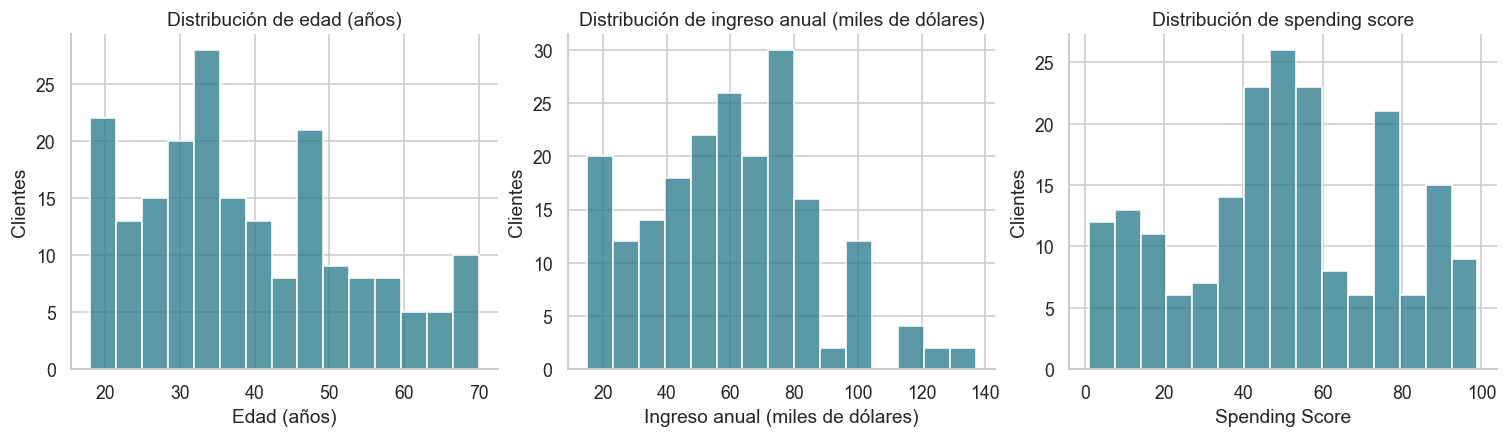

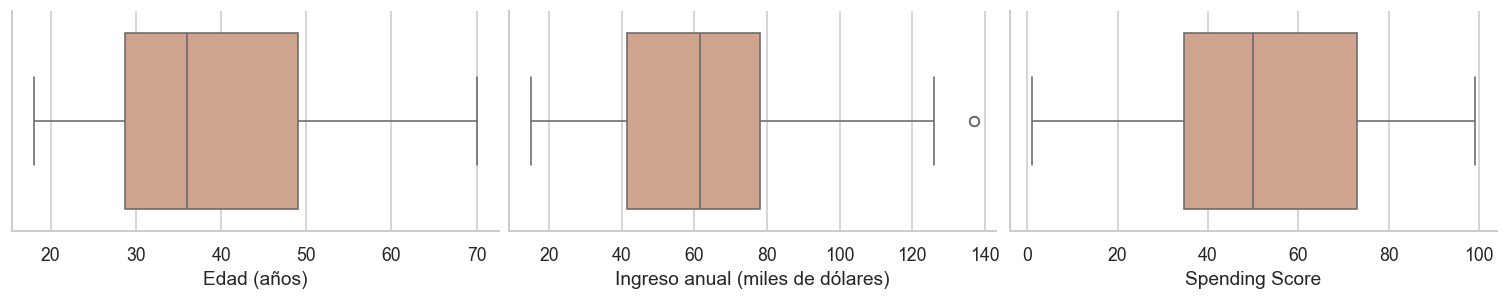

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
labels = ["Edad (años)", "Ingreso anual (miles de dólares)", "Spending Score"]
for ax, column, label in zip(axes, NUMERIC, labels):
    sns.histplot(data=df, x=column, bins=15, ax=ax, color="#267789")
    ax.set(xlabel=label, ylabel="Clientes", title=f"Distribución de {label.lower()}")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 2.5), constrained_layout=True)
for ax, column, label in zip(axes, NUMERIC, labels):
    sns.boxplot(data=df, x=column, ax=ax, color="#d9a084")
    ax.set(xlabel=label)
plt.show()

In [6]:
iqr_rows = []
outlier_masks = {}
for column in NUMERIC:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[column] < lower) | (df[column] > upper)
    outlier_masks[column] = mask
    iqr_rows.append([column, lower, upper, int(mask.sum())])
iqr_table = pd.DataFrame(iqr_rows, columns=["Variable", "Límite inferior", "Límite superior", "Atípicos"])
display(iqr_table)
display(df.loc[np.column_stack(list(outlier_masks.values())).any(axis=1)])

,Variable,Límite inferior,Límite superior,Atípicos
0,Age,-1.625,79.375,0
1,Annual Income (k$),-13.250,132.750,2
2,Spending Score (1-100),-22.625,130.375,0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


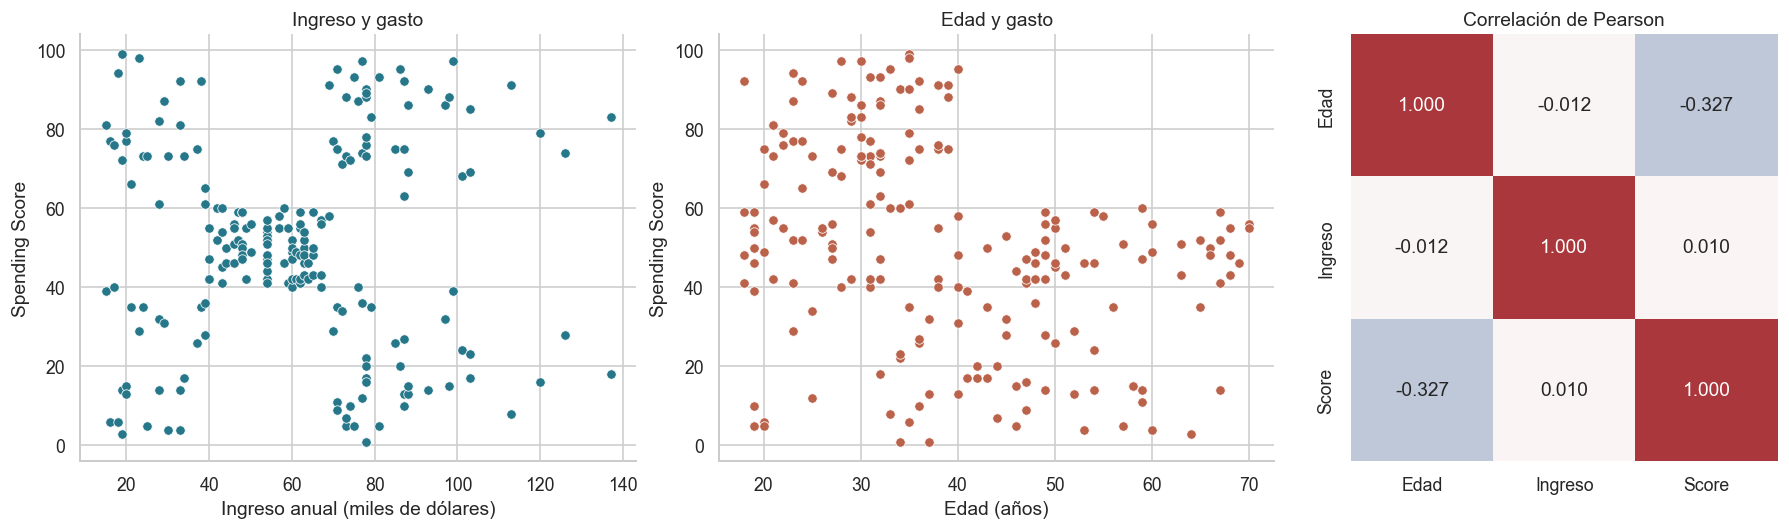

In [7]:
correlations = df[NUMERIC].corr()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
sns.scatterplot(data=df, x=FEATURES[0], y=FEATURES[1], ax=axes[0], color="#267789", s=35)
axes[0].set(xlabel="Ingreso anual (miles de dólares)", ylabel="Spending Score", title="Ingreso y gasto")
sns.scatterplot(data=df, x="Age", y=FEATURES[1], ax=axes[1], color="#bb624b", s=35)
axes[1].set(xlabel="Edad (años)", ylabel="Spending Score", title="Edad y gasto")
short_corr = correlations.rename(index=dict(zip(NUMERIC, ["Edad", "Ingreso", "Score"])),
                                 columns=dict(zip(NUMERIC, ["Edad", "Ingreso", "Score"])))
sns.heatmap(short_corr, annot=True, fmt=".3f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[2], cbar=False)
axes[2].set_title("Correlación de Pearson")
plt.show()

#### ¿Qué variables son más adecuadas para segmentar clientes?

In [8]:
display(Markdown("""
Para este trabajo se eligieron **el ingreso anual y la puntuación de gasto**. El ingreso permite conocer el nivel económico del cliente y la puntuación ayuda a comparar su comportamiento de compra. Al combinarlos se pueden encontrar grupos útiles para plantear estrategias de marketing.

No se utiliza **CustomerID**, porque es un identificador y no una característica del cliente. La **edad** se revisa para describir los grupos y más adelante se prueba como una variable adicional. El **género** no se incluye en el modelo, ya que no es necesario para la segmentación que se busca y necesitaría un tratamiento diferente por ser una categoría.
"""))


Para este trabajo se eligieron **el ingreso anual y la puntuación de gasto**. El ingreso permite conocer el nivel económico del cliente y la puntuación ayuda a comparar su comportamiento de compra. Al combinarlos se pueden encontrar grupos útiles para plantear estrategias de marketing.

No se utiliza **CustomerID**, porque es un identificador y no una característica del cliente. La **edad** se revisa para describir los grupos y más adelante se prueba como una variable adicional. El **género** no se incluye en el modelo, ya que no es necesario para la segmentación que se busca y necesitaría un tratamiento diferente por ser una categoría.


#### ¿Se identifican valores atípicos?

In [9]:
income_outliers = df.loc[outlier_masks[FEATURES[0]], ["CustomerID", FEATURES[0]]]
display(Markdown(f"""
Sí. Con la regla del rango intercuartílico, el límite superior del ingreso es **132,75 mil dólares**. Los clientes **{', '.join(income_outliers['CustomerID'].astype(str))}**, con ingresos de **137 mil dólares**, quedan por encima de ese límite. No aparecen valores atípicos en edad ni en puntuación de gasto con esta regla.

Se decidió conservarlos porque un ingreso alto no significa que el dato esté mal. Más adelante se revisa si quitarlos cambia mucho el resultado. También se comprobó que no hay datos faltantes ni filas duplicadas.
"""))


Sí. Con la regla del rango intercuartílico, el límite superior del ingreso es **132,75 mil dólares**. Los clientes **199, 200**, con ingresos de **137 mil dólares**, quedan por encima de ese límite. No aparecen valores atípicos en edad ni en puntuación de gasto con esta regla.

Se decidió conservarlos porque un ingreso alto no significa que el dato esté mal. Más adelante se revisa si quitarlos cambia mucho el resultado. También se comprobó que no hay datos faltantes ni filas duplicadas.


#### ¿Qué tipo de relaciones se observan entre las variables?

In [10]:
display(Markdown(f"""
Entre ingreso y puntuación de gasto la correlación es de **{correlations.loc[FEATURES[0], FEATURES[1]]:.3f}**, muy cercana a cero. Esto indica que tener más ingresos no siempre significa tener una puntuación de gasto más alta. En la gráfica se observan clientes con ingresos similares, pero con comportamientos de gasto diferentes.

La edad y la puntuación de gasto tienen una relación negativa de **{correlations.loc['Age', FEATURES[1]]:.3f}**: en esta muestra, los clientes más jóvenes tienden a tener una puntuación algo mayor. La relación entre edad e ingreso es casi nula. Son tendencias de los datos y no permiten asegurar que una variable sea la causa de la otra.
"""))


Entre ingreso y puntuación de gasto la correlación es de **0.010**, muy cercana a cero. Esto indica que tener más ingresos no siempre significa tener una puntuación de gasto más alta. En la gráfica se observan clientes con ingresos similares, pero con comportamientos de gasto diferentes.

La edad y la puntuación de gasto tienen una relación negativa de **-0.327**: en esta muestra, los clientes más jóvenes tienden a tener una puntuación algo mayor. La relación entre edad e ingreso es casi nula. Son tendencias de los datos y no permiten asegurar que una variable sea la causa de la otra.


## Parte 2. Preprocesamiento

Se usa `StandardScaler` para poner el ingreso y la puntuación de gasto en una escala comparable. Después de la transformación, cada variable queda con media cercana a cero y desviación estándar igual a uno.

In [11]:
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
display(pd.DataFrame({
    "Media original": scaler.mean_,
    "Desviación original (ddof=0)": scaler.scale_,
    "Media estandarizada": X_scaled.mean(axis=0),
    "Desviación estandarizada (ddof=0)": X_scaled.std(axis=0),
}, index=FEATURES).round(6))

,Media original,Desviación original (ddof=0),Media estandarizada,Desviación estandarizada (ddof=0)
Annual Income (k$),60.56,26.1990,-0.0,1.0
Spending Score (1-100),50.20,25.7589,-0.0,1.0


#### ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

In [12]:
display(Markdown("""
K-Means forma los grupos usando la distancia entre los clientes y los centros de los grupos. Si una variable maneja números mucho más grandes que otra, puede pesar más en el resultado solo por su escala.

Por eso se usa `StandardScaler`: permite comparar las dos variables en condiciones más parecidas. Esto no significa que todos los valores queden entre 0 y 1. Además, al ingresar un nuevo cliente se debe usar el mismo escalador del entrenamiento, sin volver a ajustarlo.
"""))


K-Means forma los grupos usando la distancia entre los clientes y los centros de los grupos. Si una variable maneja números mucho más grandes que otra, puede pesar más en el resultado solo por su escala.

Por eso se usa `StandardScaler`: permite comparar las dos variables en condiciones más parecidas. Esto no significa que todos los valores queden entre 0 y 1. Además, al ingresar un nuevo cliente se debe usar el mismo escalador del entrenamiento, sin volver a ajustarlo.


## Parte 3. Método del codo

Se prueban valores de K entre 1 y 10. La inercia indica qué tan cerca están los clientes del centro de su grupo. Para elegir K se busca el punto de la gráfica donde la caída empieza a ser menos marcada.

Además de observar la gráfica, se calcula una referencia del codo comparando la curva con una línea entre sus extremos. Se utiliza una semilla fija y varios intentos de entrenamiento para obtener un resultado reproducible.

,K,Inercia,Reducción (%)
0,1,400.0000,NaN
1,2,269.6910,32.5772
2,3,157.7040,41.5242
3,4,108.9213,30.9331
4,5,65.5684,39.8020
5,6,55.0573,16.0307
6,7,44.8648,18.5127
7,8,37.1481,17.1998
8,9,32.3602,12.8886
9,10,29.0762,10.1484


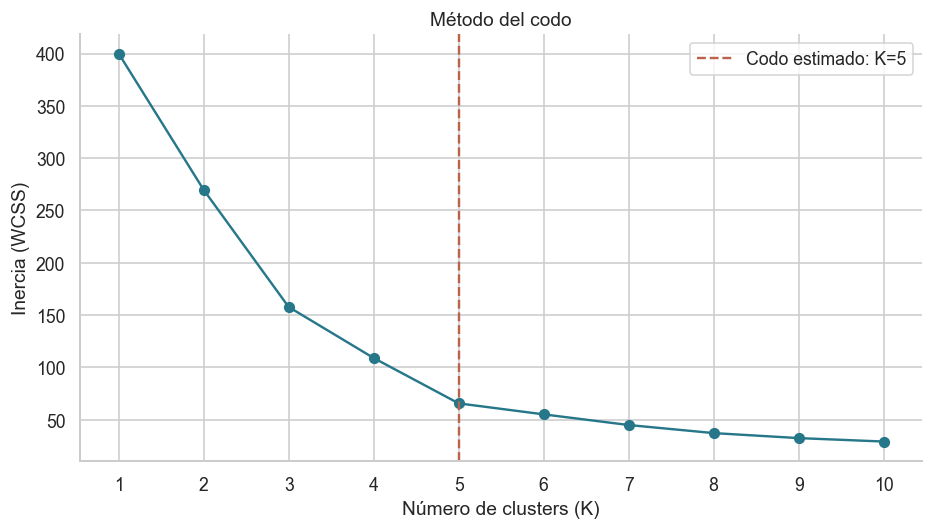

In [13]:
models = {}
for k in range(1, 11):
    models[k] = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT,
                      random_state=SEED, algorithm="lloyd").fit(X_scaled)
metrics = pd.DataFrame({"K": list(models), "Inercia": [m.inertia_ for m in models.values()]})
metrics["Reducción (%)"] = -metrics["Inercia"].pct_change() * 100
k_norm = (metrics["K"] - metrics["K"].min()) / (metrics["K"].max() - metrics["K"].min())
inertia_norm = (metrics["Inercia"] - metrics["Inercia"].min()) / (metrics["Inercia"].max() - metrics["Inercia"].min())
elbow_distance = (1 - k_norm) - inertia_norm
k_elbow = int(metrics.loc[elbow_distance.idxmax(), "K"])
display(metrics.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(metrics["K"], metrics["Inercia"], "o-", color="#267789")
ax.axvline(k_elbow, linestyle="--", color="#bb624b", label=f"Codo estimado: K={k_elbow}")
ax.set(xlabel="Número de clusters (K)", ylabel="Inercia (WCSS)", title="Método del codo", xticks=range(1, 11))
ax.legend()
plt.show()

#### ¿Por qué valores cercanos a cero indican mejor ajuste?

In [14]:
display(Markdown("""
En este caso se habla de la **inercia**. Cuando es pequeña, los clientes están más cerca del centro de su grupo, por lo que los grupos son más compactos.

Sin embargo, no se debe elegir el modelo solamente porque su inercia sea la más baja. Al aumentar K, la inercia sigue bajando; si se hiciera un grupo por cliente, podría llegar a cero y la segmentación dejaría de ser útil. Por eso se busca un equilibrio con el método del codo y se revisa también la silueta.
"""))


En este caso se habla de la **inercia**. Cuando es pequeña, los clientes están más cerca del centro de su grupo, por lo que los grupos son más compactos.

Sin embargo, no se debe elegir el modelo solamente porque su inercia sea la más baja. Al aumentar K, la inercia sigue bajando; si se hiciera un grupo por cliente, podría llegar a cero y la segmentación dejaría de ser útil. Por eso se busca un equilibrio con el método del codo y se revisa también la silueta.


#### ¿Cómo se identifica el punto óptimo de K?

In [15]:
reduction_5 = metrics.loc[metrics["K"].eq(5), "Reducción (%)"].iloc[0]
reduction_6 = metrics.loc[metrics["K"].eq(6), "Reducción (%)"].iloc[0]
display(Markdown(f"""
El punto se identifica donde la curva empieza a aplanarse. En este caso se observa un codo en **K = {k_elbow}**. Pasar de cuatro a cinco grupos reduce la inercia un **{reduction_5:.1f}%**, mientras que pasar de cinco a seis la reduce un **{reduction_6:.1f}%**.

Esto hace que cinco grupos sea una opción razonable: todavía mejora bastante la agrupación y no agrega tantos segmentos. La elección se confirma con el coeficiente de silueta.
"""))


El punto se identifica donde la curva empieza a aplanarse. En este caso se observa un codo en **K = 5**. Pasar de cuatro a cinco grupos reduce la inercia un **39.8%**, mientras que pasar de cinco a seis la reduce un **16.0%**.

Esto hace que cinco grupos sea una opción razonable: todavía mejora bastante la agrupación y no agrega tantos segmentos. La elección se confirma con el coeficiente de silueta.


## Parte 4. Coeficiente de silueta

La silueta ayuda a revisar si cada cliente está bien ubicado en su grupo y separado de los otros grupos. Sus valores están entre -1 y 1. Se calcula desde K=2, porque con un solo grupo no hay otro con el cual comparar.

,K,Inercia,Reducción (%),Silueta
0,1,400.0000,NaN,NaN
1,2,269.6910,32.5772,0.3213
2,3,157.7040,41.5242,0.4666
3,4,108.9213,30.9331,0.4939
4,5,65.5684,39.8020,0.5547
5,6,55.0573,16.0307,0.5399
6,7,44.8648,18.5127,0.5281
7,8,37.1481,17.1998,0.4567
8,9,32.3602,12.8886,0.4565
9,10,29.0762,10.1484,0.4494


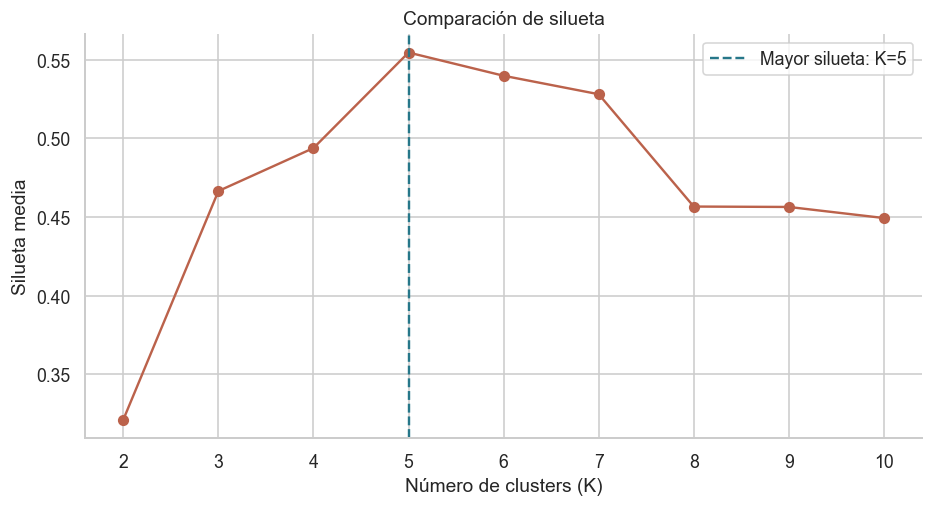

In [16]:
metrics["Silueta"] = [
    np.nan if k == 1 else silhouette_score(X_scaled, models[k].labels_)
    for k in metrics["K"]
]
selected_k = int(metrics.loc[metrics["Silueta"].idxmax(), "K"])
selected_silhouette = float(metrics.loc[metrics["K"].eq(selected_k), "Silueta"].iloc[0])
display(metrics.round(4))
fig, ax = plt.subplots(figsize=(8, 4.3), constrained_layout=True)
valid = metrics.dropna(subset=["Silueta"])
ax.plot(valid["K"], valid["Silueta"], "o-", color="#bb624b")
ax.axvline(selected_k, color="#267789", linestyle="--", label=f"Mayor silueta: K={selected_k}")
ax.set(xlabel="Número de clusters (K)", ylabel="Silueta media", title="Comparación de silueta", xticks=range(2, 11))
ax.legend()
plt.show()

#### ¿Qué mide el coeficiente de silueta?

In [17]:
display(Markdown("""
Mide qué tan parecido es un cliente a los demás de su grupo, comparado con los clientes del grupo vecino más cercano. Así permite revisar si los grupos están bien separados. Un promedio más alto suele indicar una mejor agrupación, aunque no es un porcentaje de aciertos.
"""))


Mide qué tan parecido es un cliente a los demás de su grupo, comparado con los clientes del grupo vecino más cercano. Así permite revisar si los grupos están bien separados. Un promedio más alto suele indicar una mejor agrupación, aunque no es un porcentaje de aciertos.


#### ¿Qué significa un valor cercano a 1?

In [18]:
display(Markdown("""
Un valor cercano a **1** significa que el cliente está bien ubicado: se parece más a los de su propio grupo que a los de otros grupos. Si el promedio se acerca a 1, los grupos están bien definidos y separados.
"""))


Un valor cercano a **1** significa que el cliente está bien ubicado: se parece más a los de su propio grupo que a los de otros grupos. Si el promedio se acerca a 1, los grupos están bien definidos y separados.


#### ¿Qué implica un valor cercano a 0 o negativo?

In [19]:
display(Markdown("""
Un valor cercano a **0** indica que el cliente está entre dos grupos y no hay una diferencia clara para asignarlo a uno de ellos. Un valor **negativo** significa que se parece más a otro grupo que al que se le asignó. Esos casos conviene revisarlos, aunque no necesariamente sean datos incorrectos.
"""))


Un valor cercano a **0** indica que el cliente está entre dos grupos y no hay una diferencia clara para asignarlo a uno de ellos. Un valor **negativo** significa que se parece más a otro grupo que al que se le asignó. Esos casos conviene revisarlos, aunque no necesariamente sean datos incorrectos.


#### ¿Coincide el valor óptimo de K con el método del codo? Justifique.

In [20]:
display(Markdown(f"""
**Sí, ambos métodos coinciden en K = {selected_k}.** En el codo se identifica ese punto y la silueta obtiene su valor más alto, **{selected_silhouette:.4f}**, con cinco grupos entre los valores evaluados.

Por eso se seleccionan cinco clusters. El resultado muestra una separación útil, aunque no perfecta, y los grupos se pueden interpretar según el ingreso y la puntuación de gasto.
"""))


**Sí, ambos métodos coinciden en K = 5.** En el codo se identifica ese punto y la silueta obtiene su valor más alto, **0.5547**, con cinco grupos entre los valores evaluados.

Por eso se seleccionan cinco clusters. El resultado muestra una separación útil, aunque no perfecta, y los grupos se pueden interpretar según el ingreso y la puntuación de gasto.


## Parte 5. Modelo K-Means

Se entrena el modelo con cinco grupos y se asigna un cluster a cada cliente. El escalador y K-Means se guardan juntos en un `Pipeline` para que la aplicación use los mismos pasos. Los centroides se muestran en la escala original: representan el ingreso y la puntuación de gasto promedio de cada grupo.

In [21]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=selected_k, init="k-means++", n_init=N_INIT,
                      random_state=SEED, algorithm="lloyd")),
])
pipeline.fit(X)
cluster_labels = pipeline.predict(X)
df_segmented = df.assign(Cluster=cluster_labels)
centers_scaled = pipeline["kmeans"].cluster_centers_
centers_original = pipeline["scaler"].inverse_transform(centers_scaled)
centroids = pd.DataFrame(centers_original, columns=FEATURES).rename_axis("Cluster")
assert np.array_equal(cluster_labels, models[selected_k].labels_)
display(centroids.round(4))

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.2963,49.5185
1,86.5385,82.1282
2,25.7273,79.3636
3,88.2000,17.1143
4,26.3043,20.9130


In [22]:
def name_profile(center):
    income_z, score_z = center
    if max(abs(income_z), abs(score_z)) <= 0.5:
        return "Promedio"
    if income_z > 0 and score_z > 0:
        return "Alto valor relativo"
    if income_z > 0 and score_z < 0:
        return "Potencial de crecimiento"
    if income_z < 0 and score_z < 0:
        return "Valor actual bajo"
    return "Gasto alto e ingreso bajo"

profiles = {cluster: name_profile(center) for cluster, center in enumerate(centers_scaled)}
df_segmented["Perfil"] = df_segmented["Cluster"].map(profiles)
summary = df_segmented.groupby("Cluster").agg(
    Clientes=("CustomerID", "size"),
    Edad_media=("Age", "mean"),
    Ingreso_medio=(FEATURES[0], "mean"),
    Score_medio=(FEATURES[1], "mean"),
)
summary.insert(0, "Perfil", pd.Series(profiles))
summary.insert(2, "Porcentaje", summary["Clientes"] / len(df) * 100)
display(summary.round(2))

,Perfil,Clientes,Porcentaje,Edad_media,Ingreso_medio,Score_medio
Cluster,,,,,,
0,Promedio,81,40.5,42.72,55.30,49.52
1,Alto valor relativo,39,19.5,32.69,86.54,82.13
2,Gasto alto e ingreso bajo,22,11.0,25.27,25.73,79.36
3,Potencial de crecimiento,35,17.5,41.11,88.20,17.11
4,Valor actual bajo,23,11.5,45.22,26.30,20.91


Los nombres se asignan después del entrenamiento, según las características de cada grupo. El perfil promedio queda cerca de la media en las dos variables; en el código se usa un margen de media desviación estándar. Los otros perfiles combinan ingreso y puntuación de gasto por encima o por debajo de la media. Los números de cluster solo sirven para identificarlos: el cluster 0 no es mejor ni peor que el 1.

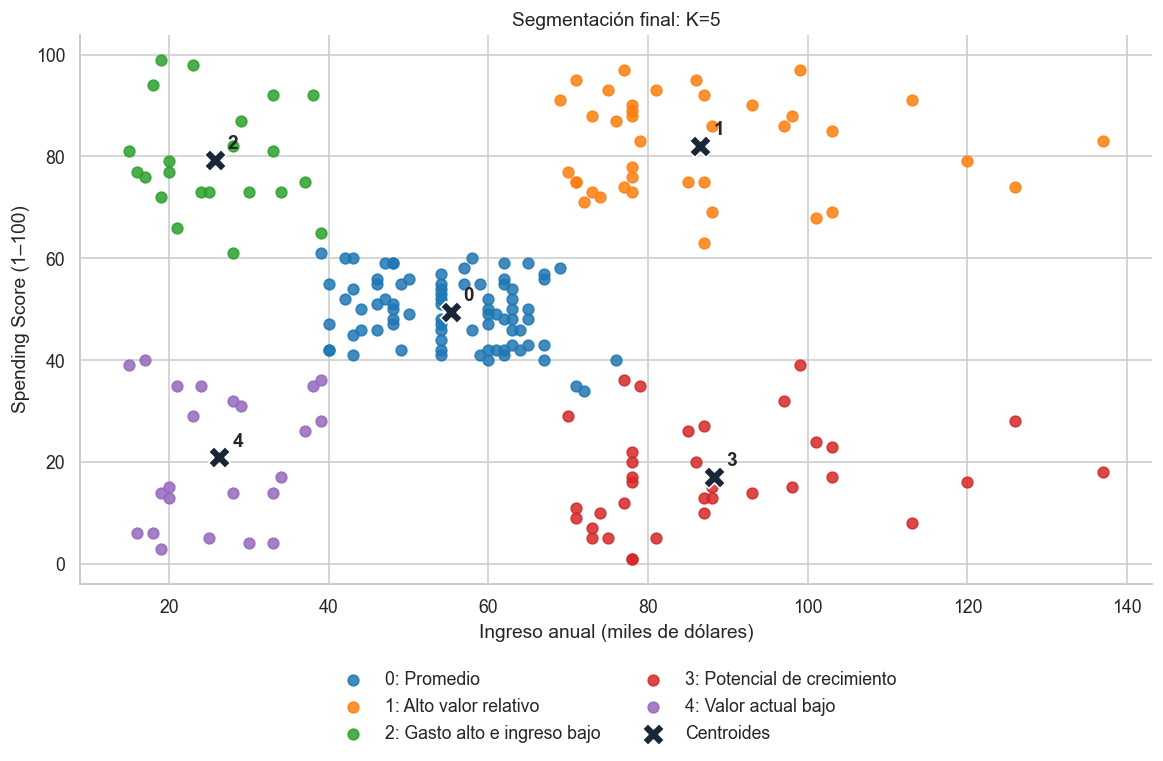

In [23]:
COLORS = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
for cluster, profile in profiles.items():
    part = df_segmented.loc[df_segmented["Cluster"].eq(cluster)]
    ax.scatter(part[FEATURES[0]], part[FEATURES[1]], s=45, alpha=0.85,
               color=COLORS(cluster), label=f"{cluster}: {profile}")
ax.scatter(centers_original[:, 0], centers_original[:, 1], marker="X", s=190,
           color="#182637", edgecolor="white", label="Centroides", zorder=5)
for cluster, (income, score) in enumerate(centers_original):
    ax.annotate(str(cluster), (income, score), xytext=(8, 7), textcoords="offset points", weight="bold")
ax.set(xlabel="Ingreso anual (miles de dólares)", ylabel="Spending Score (1–100)",
       title=f"Segmentación final: K={selected_k}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
plt.show()

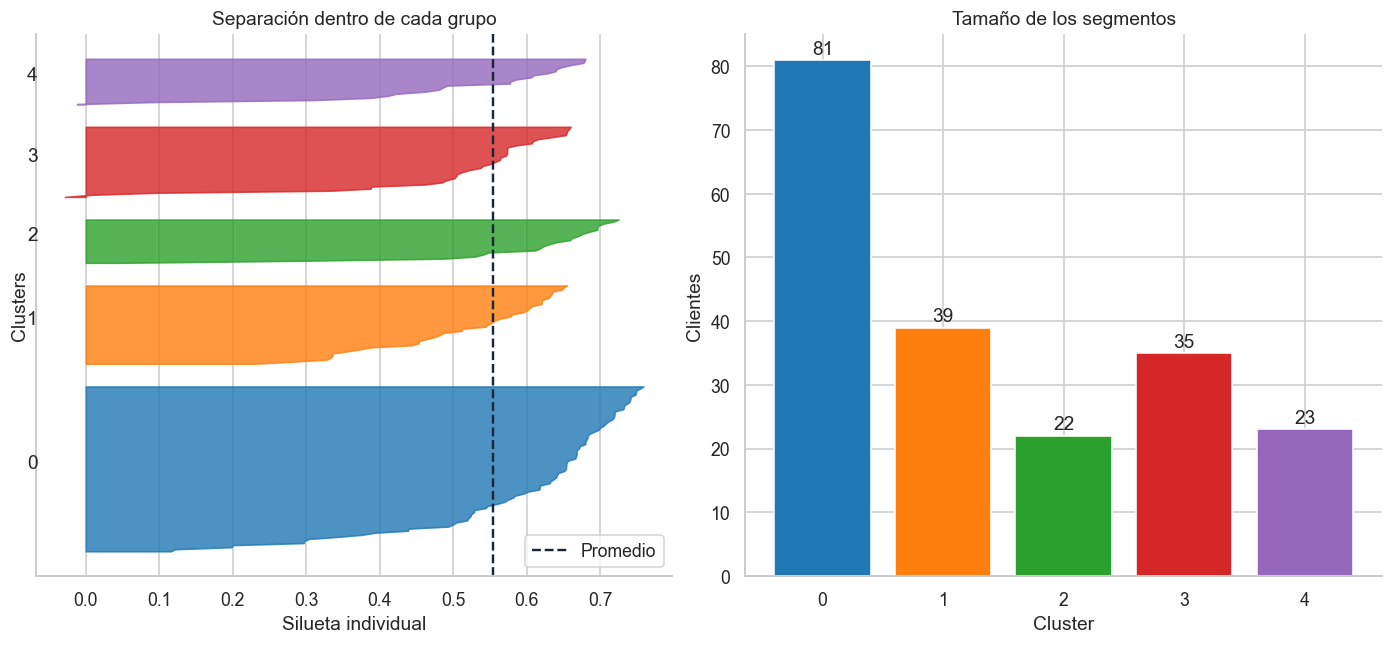

Silueta negativa: 2 de 200 clientes.


In [24]:
silhouette_values = silhouette_samples(X_scaled, cluster_labels)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
y_lower = 10
for cluster in range(selected_k):
    values = np.sort(silhouette_values[cluster_labels == cluster])
    y_upper = y_lower + len(values)
    axes[0].fill_betweenx(np.arange(y_lower, y_upper), 0, values, color=COLORS(cluster), alpha=0.8)
    axes[0].text(-0.08, (y_lower + y_upper) / 2, str(cluster))
    y_lower = y_upper + 10
axes[0].axvline(selected_silhouette, color="#182637", linestyle="--", label="Promedio")
axes[0].set(xlabel="Silueta individual", ylabel="Clusters", title="Separación dentro de cada grupo", yticks=[])
axes[0].legend()
axes[1].bar(summary.index.astype(str), summary["Clientes"], color=[COLORS(i) for i in summary.index])
axes[1].set(xlabel="Cluster", ylabel="Clientes", title="Tamaño de los segmentos")
for i, count in zip(summary.index, summary["Clientes"]):
    axes[1].text(i, count + 1, str(count), ha="center")
plt.show()
print(f"Silueta negativa: {(silhouette_values < 0).sum()} de {len(df)} clientes.")

#### ¿Qué representa cada cluster?

In [25]:
for cluster, row in summary.iterrows():
    display(Markdown(
        f"**Cluster {cluster}: {row['Perfil']}.** {int(row['Clientes'])} clientes "
        f"({row['Porcentaje']:.1f}%); ingreso medio **{row['Ingreso_medio']:.2f} mil dólares**, "
        f"puntuación media **{row['Score_medio']:.2f}** y edad media **{row['Edad_media']:.1f} años**."
    ))

**Cluster 0: Promedio.** 81 clientes (40.5%); ingreso medio **55.30 mil dólares**, puntuación media **49.52** y edad media **42.7 años**.

**Cluster 1: Alto valor relativo.** 39 clientes (19.5%); ingreso medio **86.54 mil dólares**, puntuación media **82.13** y edad media **32.7 años**.

**Cluster 2: Gasto alto e ingreso bajo.** 22 clientes (11.0%); ingreso medio **25.73 mil dólares**, puntuación media **79.36** y edad media **25.3 años**.

**Cluster 3: Potencial de crecimiento.** 35 clientes (17.5%); ingreso medio **88.20 mil dólares**, puntuación media **17.11** y edad media **41.1 años**.

**Cluster 4: Valor actual bajo.** 23 clientes (11.5%); ingreso medio **26.30 mil dólares**, puntuación media **20.91** y edad media **45.2 años**.

#### ¿Qué diferencias existen entre los grupos obtenidos?

In [26]:
display(Markdown("""
La diferencia principal está en la combinación de ingreso y gasto. Hay un grupo con valores intermedios y otros cuatro que combinan ingresos altos o bajos con puntuaciones de gasto altas o bajas.

Esto muestra que no todos los clientes con ingresos altos gastan igual y que también hay clientes con ingresos bajos y una puntuación de gasto alta. La edad ayuda a describirlos: por ejemplo, el grupo de ingreso bajo y gasto alto es más joven en promedio. Aun así, la edad no se usó para asignar los cinco grupos del modelo final.
"""))


La diferencia principal está en la combinación de ingreso y gasto. Hay un grupo con valores intermedios y otros cuatro que combinan ingresos altos o bajos con puntuaciones de gasto altas o bajas.

Esto muestra que no todos los clientes con ingresos altos gastan igual y que también hay clientes con ingresos bajos y una puntuación de gasto alta. La edad ayuda a describirlos: por ejemplo, el grupo de ingreso bajo y gasto alto es más joven en promedio. Aun así, la edad no se usó para asignar los cinco grupos del modelo final.


### Comprobación adicional

Se repite el entrenamiento con distintas semillas y se revisa qué pasa al quitar los dos ingresos atípicos. Para comparar los resultados se utiliza el índice ARI: un valor de 1 significa que las asignaciones coinciden por completo. También se prueba agregar la edad al modelo.

In [27]:
seed_results = []
for seed in range(10):
    alternative = KMeans(n_clusters=selected_k, n_init=N_INIT, random_state=seed).fit_predict(X_scaled)
    seed_results.append([seed, adjusted_rand_score(cluster_labels, alternative)])
stability = pd.DataFrame(seed_results, columns=["Semilla", "ARI frente al modelo final"])

keep = ~outlier_masks[FEATURES[0]]
X_without = StandardScaler().fit_transform(X.loc[keep])
sensitivity_rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X_without)
    sensitivity_rows.append([k, silhouette_score(X_without, labels)])
sensitivity = pd.DataFrame(sensitivity_rows, columns=["K", "Silueta sin atípicos"])
k_without = int(sensitivity.loc[sensitivity["Silueta sin atípicos"].idxmax(), "K"])
labels_without = KMeans(n_clusters=selected_k, n_init=N_INIT, random_state=SEED).fit_predict(X_without)
outlier_ari = adjusted_rand_score(cluster_labels[keep], labels_without)

X_with_age = StandardScaler().fit_transform(df[NUMERIC])
age_rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X_with_age)
    age_rows.append([k, silhouette_score(X_with_age, labels)])
age_metrics = pd.DataFrame(age_rows, columns=["K", "Silueta con edad"])
k_age = int(age_metrics.loc[age_metrics["Silueta con edad"].idxmax(), "K"])
display(stability)
display(sensitivity.merge(age_metrics, on="K").round(4))
display(Markdown(f"""
Al repetir el entrenamiento con diez semillas, las asignaciones coinciden con el modelo final (**ARI mínimo = {stability.iloc[:, 1].min():.4f}**). Al quitar los dos ingresos atípicos, el mejor número de grupos sigue siendo **{k_without}** y la comparación de los clientes restantes da un **ARI de {outlier_ari:.4f}**. Esto indica que esos dos registros no cambian mucho la segmentación.

Al agregar la edad, la silueta más alta aparece con **{k_age} grupos**, con un valor de **{age_metrics['Silueta con edad'].max():.4f}**. Se mantiene el modelo de ingreso y gasto porque responde al objetivo del taller y sus perfiles son más fáciles de explicar. Las siluetas de modelos con variables diferentes no se deben comparar como si midieran exactamente lo mismo.

Estas pruebas dan más confianza en el resultado de esta muestra, pero todavía sería necesario revisar datos de otros clientes o periodos.
"""))

,Semilla,ARI frente al modelo final
0,0,1.0
1,1,1.0
2,2,1.0
3,3,1.0
4,4,1.0
5,5,1.0
6,6,1.0
7,7,1.0
8,8,1.0
9,9,1.0


,K,Silueta sin atípicos,Silueta con edad
0,2,0.3034,0.3355
1,3,0.4667,0.3578
2,4,0.4967,0.4040
3,5,0.5599,0.4166
4,6,0.4655,0.4274
5,7,0.4563,0.4172
6,8,0.4579,0.4087
7,9,0.4590,0.4201
8,10,0.4523,0.3973



Al repetir el entrenamiento con diez semillas, las asignaciones coinciden con el modelo final (**ARI mínimo = 1.0000**). Al quitar los dos ingresos atípicos, el mejor número de grupos sigue siendo **5** y la comparación de los clientes restantes da un **ARI de 0.9846**. Esto indica que esos dos registros no cambian mucho la segmentación.

Al agregar la edad, la silueta más alta aparece con **6 grupos**, con un valor de **0.4274**. Se mantiene el modelo de ingreso y gasto porque responde al objetivo del taller y sus perfiles son más fáciles de explicar. Las siluetas de modelos con variables diferentes no se deben comparar como si midieran exactamente lo mismo.

Estas pruebas dan más confianza en el resultado de esta muestra, pero todavía sería necesario revisar datos de otros clientes o periodos.


## Parte 6. Interpretación de negocio

Se describen cinco perfiles porque ese fue el número de grupos elegido. Los tipos mencionados en el enunciado sirven como referencia para ponerles un nombre. En este análisis, hablar de valor alto o bajo se refiere a la puntuación de gasto; no se cuenta con ventas ni ganancias reales para calcular la rentabilidad de cada cliente.

In [28]:
strategies_by_profile = {
    "Alto valor relativo": "Ofrecer beneficios de fidelización, atención personalizada y acceso anticipado a productos. Revisar si estos clientes siguen comprando y responden a las ofertas.",
    "Potencial de crecimiento": "Investigar por qué compran poco y probar recomendaciones o promociones de reactivación. Comparar sus compras antes y después de la campaña.",
    "Promedio": "Usar programas de puntos, paquetes de productos y promociones para aumentar la frecuencia de compra. Revisar si regresan más seguido y si aumenta el valor de sus compras.",
    "Valor actual bajo": "Utilizar promociones sencillas y comunicaciones de bajo costo. Evaluar su respuesta antes de invertir más en campañas para este grupo.",
    "Gasto alto e ingreso bajo": "Ofrecer beneficios de fidelización y promociones que les resulten útiles. Buscar que sigan comprando sin depender de descuentos constantes.",
}
strategies = {cluster: strategies_by_profile[name] for cluster, name in profiles.items()}
marketing = summary[["Perfil", "Clientes", "Porcentaje"]].copy()
marketing["Estrategia"] = pd.Series(strategies)
display(marketing)

,Perfil,Clientes,Porcentaje,Estrategia
Cluster,,,,
0,Promedio,81,40.5,"Usar programas de puntos, paquetes de producto..."
1,Alto valor relativo,39,19.5,"Ofrecer beneficios de fidelización, atención p..."
2,Gasto alto e ingreso bajo,22,11.0,Ofrecer beneficios de fidelización y promocion...
3,Potencial de crecimiento,35,17.5,Investigar por qué compran poco y probar recom...
4,Valor actual bajo,23,11.5,Utilizar promociones sencillas y comunicacione...


#### ¿Qué estrategias de marketing se podrían aplicar a cada grupo?

In [29]:
for cluster, profile in profiles.items():
    display(Markdown(f"**{profile} (cluster {cluster}):** {strategies[cluster]}"))
display(Markdown("Estas estrategias son propuestas basadas en los perfiles. Para saber si funcionan, se pueden comparar campañas con un grupo que reciba la oferta y otro que no, revisando compras, frecuencia y ganancias reales."))

**Promedio (cluster 0):** Usar programas de puntos, paquetes de productos y promociones para aumentar la frecuencia de compra. Revisar si regresan más seguido y si aumenta el valor de sus compras.

**Alto valor relativo (cluster 1):** Ofrecer beneficios de fidelización, atención personalizada y acceso anticipado a productos. Revisar si estos clientes siguen comprando y responden a las ofertas.

**Gasto alto e ingreso bajo (cluster 2):** Ofrecer beneficios de fidelización y promociones que les resulten útiles. Buscar que sigan comprando sin depender de descuentos constantes.

**Potencial de crecimiento (cluster 3):** Investigar por qué compran poco y probar recomendaciones o promociones de reactivación. Comparar sus compras antes y después de la campaña.

**Valor actual bajo (cluster 4):** Utilizar promociones sencillas y comunicaciones de bajo costo. Evaluar su respuesta antes de invertir más en campañas para este grupo.

Estas estrategias son propuestas basadas en los perfiles. Para saber si funcionan, se pueden comparar campañas con un grupo que reciba la oferta y otro que no, revisando compras, frecuencia y ganancias reales.

#### ¿Qué segmento representa mayor oportunidad de crecimiento?

In [30]:
growth_cluster = next(k for k, name in profiles.items() if name == "Potencial de crecimiento")
growth = summary.loc[growth_cluster]
display(Markdown(f"""
El grupo con mayor oportunidad de crecimiento es el de **ingreso alto y puntuación de gasto baja**, llamado **Potencial de crecimiento**. Tiene **{int(growth['Clientes'])} clientes**, que representan el **{growth['Porcentaje']:.1f}%** de la muestra. Su ingreso promedio es de **{growth['Ingreso_medio']:.2f} mil dólares** y su puntuación de gasto promedio es de **{growth['Score_medio']:.2f}**.

Podría ser una oportunidad porque sus ingresos son altos, pero su participación de gasto es baja. Se podrían investigar sus preferencias y probar campañas que les den más motivos para comprar. Esto no asegura que vayan a gastar más; habría que comprobarlo con los resultados de las campañas y con datos reales de ventas.
"""))


El grupo con mayor oportunidad de crecimiento es el de **ingreso alto y puntuación de gasto baja**, llamado **Potencial de crecimiento**. Tiene **35 clientes**, que representan el **17.5%** de la muestra. Su ingreso promedio es de **88.20 mil dólares** y su puntuación de gasto promedio es de **17.11**.

Podría ser una oportunidad porque sus ingresos son altos, pero su participación de gasto es baja. Se podrían investigar sus preferencias y probar campañas que les den más motivos para comprar. Esto no asegura que vayan a gastar más; habría que comprobarlo con los resultados de las campañas y con datos reales de ventas.


## Parte 7. Despliegue con Streamlit

La aplicación muestra el método del codo, la silueta, los grupos y sus centroides. También permite ingresar el ingreso y la puntuación de gasto de un nuevo cliente para asignarlo a un cluster.

Se guarda el modelo junto con su escalador para que las predicciones usen el mismo proceso del entrenamiento. Los archivos de datos y resultados se incluyen en el paquete de la aplicación.

In [31]:
examples = pd.DataFrame([
    [90, 85], [90, 15], [25, 85], [25, 15], [55, 50]
], columns=FEATURES)
scaler_before = pipeline["scaler"].mean_.copy()
examples["Cluster"] = pipeline.predict(examples[FEATURES])
examples["Perfil"] = examples["Cluster"].map(profiles)
assert np.array_equal(scaler_before, pipeline["scaler"].mean_)
display(examples)

,Annual Income (k$),Spending Score (1-100),Cluster,Perfil
0,90,85,1,Alto valor relativo
1,90,15,3,Potencial de crecimiento
2,25,85,2,Gasto alto e ingreso bajo
3,25,15,4,Valor actual bajo
4,55,50,0,Promedio


In [32]:
PACKAGE = Path("proyecto_streamlit")
PACKAGE.mkdir(exist_ok=True)
(PACKAGE / ".streamlit").mkdir(exist_ok=True)
(PACKAGE / "Mall_Customers.csv").write_bytes(csv_bytes)
joblib.dump(pipeline, PACKAGE / "modelo_kmeans.joblib")
metrics.to_csv(PACKAGE / "metricas_k.csv", index=False)
summary.reset_index().to_csv(PACKAGE / "perfiles.csv", index=False)
df_segmented.to_csv(PACKAGE / "clientes_segmentados.csv", index=False)
model_metadata = {
    "features": FEATURES,
    "selected_k": selected_k,
    "elbow_k": k_elbow,
    "silhouette": selected_silhouette,
    "profiles": {str(k): v for k, v in profiles.items()},
    "strategies": {str(k): v for k, v in strategies.items()},
    "dataset_sha256": EXPECTED_SHA256,
    "dataset_source": SOURCE_URL,
    "seed": SEED,
    "n_init": N_INIT,
    "versions": versions,
}
(PACKAGE / "metadata.json").write_text(json.dumps(model_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
(PACKAGE / "requirements.txt").write_text("".join(f"{name}=={version}\n" for name, version in versions.items()), encoding="utf-8")
(PACKAGE / ".streamlit" / "config.toml").write_text(
    '[theme]\nprimaryColor = "#267789"\nbackgroundColor = "#ffffff"\n'
    'secondaryBackgroundColor = "#f1f5f6"\ntextColor = "#182637"\nfont = "sans serif"\n', encoding="utf-8"
)
stability.to_csv(RESULTS / "estabilidad_semillas.csv", index=False)
sensitivity.merge(age_metrics, on="K").to_csv(RESULTS / "sensibilidad.csv", index=False)
print("Modelo, datos y resultados exportados.")

Modelo, datos y resultados exportados.


In [33]:
%%writefile proyecto_streamlit/app.py
from pathlib import Path
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st


st.set_page_config(page_title="Segmentación de clientes", page_icon="◈", layout="wide")
ROOT = Path(__file__).resolve().parent


@st.cache_resource
def load_assets():
    data_path = ROOT / "Mall_Customers.csv"
    metadata = json.loads((ROOT / "metadata.json").read_text(encoding="utf-8"))
    if hashlib.sha256(data_path.read_bytes()).hexdigest() != metadata["dataset_sha256"]:
        raise ValueError("El CSV no corresponde a los datos con los que se entrenó el modelo.")
    data = pd.read_csv(data_path)
    pipeline = joblib.load(ROOT / "modelo_kmeans.joblib")
    features = metadata["features"]
    if list(pipeline.feature_names_in_) != features:
        raise ValueError("Las variables del modelo no coinciden con los metadatos.")
    data["Cluster"] = pipeline.predict(data[features])
    names = {int(k): v for k, v in metadata["profiles"].items()}
    data["Perfil"] = data["Cluster"].map(names)
    metrics = pd.read_csv(ROOT / "metricas_k.csv")
    centers = pipeline["scaler"].inverse_transform(pipeline["kmeans"].cluster_centers_)
    return data, pipeline, metadata, metrics, centers, names


def cluster_plot(data, centers, names, new_customer=None):
    fig, ax = plt.subplots(figsize=(9, 5.8), constrained_layout=True)
    colors = plt.get_cmap("tab10")
    for cluster, name in sorted(names.items()):
        part = data.loc[data["Cluster"] == cluster]
        ax.scatter(part[features[0]], part[features[1]], s=46, alpha=0.8,
                   color=colors(cluster), label=f"{cluster}: {name}")
    ax.scatter(centers[:, 0], centers[:, 1], color="#182637", marker="X",
               s=180, linewidths=1, edgecolors="white", label="Centroides", zorder=4)
    if new_customer is not None:
        ax.scatter([new_customer[0]], [new_customer[1]], color="#e63946",
                   marker="*", s=360, edgecolors="black", linewidths=0.8,
                   label="Nuevo cliente", zorder=5)
    ax.set(xlabel="Ingreso anual (miles de dólares)", ylabel="Spending Score (1–100)",
           title="Segmentos por ingreso y puntuación de gasto", ylim=(-3, 104))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2,
              fontsize=8, frameon=False)
    return fig


try:
    data, pipeline, metadata, metrics, centers, names = load_assets()
except (OSError, ValueError, KeyError) as exc:
    st.error(f"No se pudo cargar el proyecto: {exc}")
    st.stop()

features = metadata["features"]
selected_k = metadata["selected_k"]
st.title("Segmentación de clientes")
st.write("Explora cinco perfiles de Mall Customers y asigna un nuevo cliente con K-Means.")
a, b, c = st.columns(3)
a.metric("Clientes analizados", len(data))
b.metric("Segmentos", selected_k)
c.metric("Silueta media", f"{metadata['silhouette']:.3f}")
st.caption("Ingreso anual expresado en miles de dólares. Spending Score es una puntuación, no un importe de compra.")

tab_segments, tab_k, tab_new, tab_data = st.tabs(
    ["Segmentos", "Selección de K", "Nuevo cliente", "Datos"]
)

with tab_segments:
    fig = cluster_plot(data, centers, names)
    st.pyplot(fig)
    plt.close(fig)
    st.subheader("Perfil de cada grupo")
    summary = pd.read_csv(ROOT / "perfiles.csv")
    st.dataframe(summary.round(2), hide_index=True, width="stretch")
    chosen = st.selectbox("Consultar estrategia", options=sorted(names),
                          format_func=lambda k: f"{k}: {names[k]}")
    st.info(metadata["strategies"][str(chosen)])
    st.caption("Los perfiles se basan en el ingreso y la puntuación de gasto. No indican las ganancias reales de cada cliente.")

with tab_k:
    st.subheader("Comparación de 1 a 10 grupos")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    axes[0].plot(metrics["K"], metrics["Inercia"], "o-", color="#267789")
    axes[0].set(title="Método del codo", xlabel="K", ylabel="Inercia (WCSS)")
    valid = metrics.dropna(subset=["Silueta"])
    axes[1].plot(valid["K"], valid["Silueta"], "o-", color="#bb624b")
    axes[1].set(title="Coeficiente de silueta", xlabel="K", ylabel="Silueta media")
    for ax in axes:
        ax.axvline(selected_k, color="#182637", linestyle="--", label=f"K elegido = {selected_k}")
        ax.set_xticks(metrics["K"])
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False)
        ax.grid(alpha=0.15)
    st.pyplot(fig)
    plt.close(fig)
    st.write(f"Se elige K = {selected_k}: coincide el codo estimado con la mayor silueta entre K = 2 y K = 10.")
    st.caption("La inercia disminuye al agregar grupos; minimizarla por sí sola no permite elegir K. La silueta no está definida para K = 1.")
    st.dataframe(metrics.round(4), hide_index=True, width="stretch")

with tab_new:
    st.subheader("Asignar un nuevo cliente")
    st.write("Se utiliza el mismo escalador y el mismo modelo entrenado en el cuaderno.")
    with st.form("new_customer"):
        income = st.number_input("Ingreso anual (miles de dólares)", min_value=0.0,
                                 value=60.0, step=1.0)
        spending = st.number_input("Spending Score (1–100)", min_value=1.0,
                                   max_value=100.0, value=50.0, step=1.0)
        submitted = st.form_submit_button("Clasificar cliente", type="primary")
    if submitted:
        if not np.isfinite([income, spending]).all():
            st.error("Ingresa valores numéricos finitos.")
            st.stop()
        customer = pd.DataFrame([[income, spending]], columns=features)
        cluster = int(pipeline.predict(customer)[0])
        distance = float(pipeline.transform(customer)[0, cluster])
        st.success(f"Cluster {cluster}: {names[cluster]}")
        st.write(metadata["strategies"][str(cluster)])
        outside = [feature for feature in features
                   if not data[feature].min() <= customer.iloc[0][feature] <= data[feature].max()]
        if outside:
            st.warning("El cliente tiene valores fuera del rango de los datos utilizados. Revisa la asignación con cuidado.")
        st.caption(f"Distancia al centroide en el espacio estandarizado: {distance:.3f}. Una distancia menor indica mayor cercanía al centro del grupo; no es un porcentaje de acierto.")
        fig = cluster_plot(data, centers, names, (income, spending))
        st.pyplot(fig)
        plt.close(fig)

with tab_data:
    st.subheader("Clientes y asignaciones")
    selected = st.multiselect("Filtrar segmentos", options=sorted(names), default=sorted(names),
                             format_func=lambda k: names[k])
    filtered = data.loc[data["Cluster"].isin(selected)]
    st.dataframe(filtered, hide_index=True, width="stretch")
    st.download_button("Descargar clientes filtrados", data=filtered.to_csv(index=False).encode("utf-8-sig"),
                       file_name="clientes_segmentados.csv", mime="text/csv")
    st.markdown("[Fuente del dataset: Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)")
    st.caption("Resultados basados en 200 clientes. Las estrategias se deben comprobar con datos de compras y campañas.")


Overwriting proyecto_streamlit/app.py


In [34]:
readme = f'''# Segmentación de clientes con K-Means

Trabajo del taller final de Minería de Datos.\n\n[Abrir en Colab](https://colab.research.google.com/github/Jacklb19/K-means/blob/main/Taller_Final_KMeans.ipynb)\n\nModelo: {len(df)} clientes, K={selected_k}, silueta={selected_silhouette:.4f}.
Variables: ingreso anual en miles de dólares y Spending Score (1–100).

## Abrir el cuaderno en Colab

1. Entra en https://colab.research.google.com/ y elige Archivo > Subir cuaderno.
2. Sube Taller_Final_KMeans.ipynb.
3. Usa un entorno nuevo de Python 3 con CPU y ejecuta todas las celdas en orden.
4. La última celda descarga de nuevo este paquete con el modelo de esa ejecución.

## Desplegar en Streamlit Community Cloud

1. Abre el repositorio https://github.com/Jacklb19/K-means.
2. Los archivos de la aplicación están en la raíz. Si partes del ZIP, descomprímelo y sube su contenido, conservando .streamlit/config.toml. El archivo app.py debe quedar en la raíz junto a requirements.txt, Mall_Customers.csv, modelo_kmeans.joblib, metadata.json, metricas_k.csv y perfiles.csv. clientes_segmentados.csv sirve como resultado adicional.
3. Entra en https://share.streamlit.io/ e inicia sesión con GitHub. Conecta tu cuenta si se solicita.
4. Selecciona Create app y elige la opción de una aplicación existente.
5. Indica el repositorio Jacklb19/K-means, la rama main y app.py como archivo principal.
6. En Advanced settings selecciona Python 3.12. No hacen falta secretos ni credenciales de Kaggle.
7. Pulsa Deploy. Cuando termine la instalación, abre el enlace generado.
8. En Nuevo cliente prueba ingreso 90 y score 85: debe asignarse a Alto valor relativo. Prueba también 90 y 15: debe asignarse a Potencial de crecimiento.

Si vuelves a entrenar, reemplaza juntos el modelo, el CSV, metadata.json, metricas_k.csv, perfiles.csv y requirements.txt con los archivos de la nueva exportación.

## Ejecutar localmente

Con Python 3.12, abre una terminal en la carpeta extraída y ejecuta:

```text
python -m venv .venv
```

Activa el entorno: en Windows usa `.venv\\Scripts\\activate`; en macOS/Linux usa `source .venv/bin/activate`.

```text
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Abre la dirección local que indique Streamlit.

## Interpretación

Los grupos se basan en el ingreso y la puntuación de gasto. El score no es un importe de compra, por lo que los perfiles no indican las ganancias reales de cada cliente. La aplicación utiliza el mismo modelo y escalador del cuaderno y avisa si un cliente tiene valores fuera del rango de los datos.

Fuente de datos: {SOURCE_URL}

Documentación de despliegue: https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy

Dependencias: https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/app-dependencies
'''
(PACKAGE / "README.md").write_text(readme, encoding="utf-8")

reloaded = joblib.load(PACKAGE / "modelo_kmeans.joblib")
assert np.array_equal(reloaded.predict(X), cluster_labels)
assert np.array_equal(reloaded.predict(examples[FEATURES]), examples["Cluster"].to_numpy())
assert summary["Clientes"].sum() == len(df)
assert metrics.loc[metrics["K"].eq(1), "Silueta"].isna().all()
assert len(set(profiles.values())) == selected_k
assert k_elbow == selected_k == 5
assert (PACKAGE / "app.py").exists()
print("Verificaciones correctas: modelo guardado, predicciones, perfiles y selección de K.")

ZIP_PATH = Path("Streamlit_KMeans.zip")
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file in sorted(PACKAGE.rglob("*")):
        if file.is_file():
            archive.write(file, file.relative_to(PACKAGE))
print(f"Paquete listo: {ZIP_PATH.name}")

Verificaciones correctas: modelo guardado, predicciones, perfiles y selección de K.
Paquete listo: Streamlit_KMeans.zip


### Cómo desplegar la aplicación

1. Revisa que los archivos de la aplicación estén en la raíz del [repositorio de GitHub](https://github.com/Jacklb19/K-means).
2. Entra en [Streamlit Community Cloud](https://share.streamlit.io/) e inicia sesión con GitHub.
3. Pulsa **Create app** y selecciona el repositorio **Jacklb19/K-means**, la rama **main** y el archivo **app.py**.
4. En **Advanced settings**, selecciona **Python 3.12** y pulsa **Deploy**. No se necesitan claves de Kaggle.
5. Cuando la aplicación esté lista, prueba un cliente con ingreso **90** y puntuación de gasto **85**. Debe quedar en el perfil **Alto valor relativo**.

Si se ejecuta el cuaderno en Colab, la última celda descarga un ZIP con todos los archivos de la aplicación. Las instrucciones para ejecutarla localmente están en `README.md`.

Referencia: [documentación de Streamlit](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy).

## Conclusiones

- El ingreso y la puntuación de gasto permitieron identificar cinco grupos de clientes con características diferentes.
- El codo y la silueta coincidieron en elegir K=5. La silueta fue de aproximadamente 0,555, lo que muestra una separación útil, aunque algunos clientes quedan cerca de los límites entre grupos.
- Los dos ingresos atípicos no cambiaron mucho el resultado, por lo que se conservaron en el análisis principal.
- El grupo de ingreso alto y gasto bajo puede ser una oportunidad para plantear campañas y tratar de aumentar su participación. Esto se debe comprobar con resultados reales de compras.
- La aplicación de Streamlit permite consultar los grupos y asignar nuevos clientes usando el modelo entrenado.

**Fuentes consultadas:** [dataset en Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python), [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) y [coeficiente de silueta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

In [35]:
try:
    from google.colab import files
except ImportError:
    display(FileLink(str(ZIP_PATH)))
else:
    files.download(str(ZIP_PATH))

C:\Users\josel\Documents\Codex\2026-10-22\que-x20\work\ejecucion\Streamlit_KMeans.zip